# 04 · Eksperimen dan Optimasi Hyperparameter
## Estimasi Harga Rumah California dengan MLP Regresi

Notebook 03 menghasilkan model **baseline** (13 → 128 → 64 → 32 → 1, L2 `1e-4`, Dropout 0,2). Notebook ini mencari secara
sistematis apakah ada konfigurasi yang **benar-benar** lebih baik, dan menjaga agar kesimpulannya jujur.

### Protokol eksperimen

| # | Aturan | Alasan |
|---|---|---|
| 1 | Hanya **satu faktor** diubah per eksperimen, dari baseline (*one-factor-at-a-time*) | Pengaruh tiap faktor bisa dibaca terpisah |
| 2 | Pemilihan memakai **MAE validation dalam USD**, bukan `val_loss` | `val_loss` memuat penalti L2 (nilainya tidak sebanding antar nilai L2) dan berada pada skala log bila target di-log |
| 3 | Baseline dilatih dengan **beberapa seed** untuk mengukur *noise* acak | Selisih yang lebih kecil dari noise tidak boleh dianggap perbaikan |
| 4 | Faktor dipilih hanya jika perbaikannya **melebihi ambang** (noise antar-seed, minimal 0,5% dari MAE baseline); selain itu tetap pakai nilai baseline | Menghindari memilih keberuntungan acak, dan memilih yang lebih sederhana |
| 5 | Kombinasi faktor terpilih diuji ulang dengan **semua seed** | Faktor yang bagus sendirian belum tentu bagus bersama |
| 6 | **Test dipakai sekali**, di bagian akhir, hanya untuk melaporkan | Test tidak ikut menentukan pilihan apa pun |

### Isi notebook

| Bagian | Isi |
|---|---|
| 1 | Data, preprocessing (dengan opsi fitur rasio), dan verifikasi terhadap notebook 02 |
| 2 | Fungsi pelatihan dan pencatat hasil (hasil disimpan bertahap ke CSV) |
| 3 | *Screening*: 7 faktor, tiap nilai dicoba satu per satu |
| 4 | Mengukur noise antar-seed dan memilih nilai terbaik per faktor |
| 5 | Menguji kombinasi dengan beberapa seed, lalu memilih model final |
| 6 | Evaluasi final pada test dan perbandingan dengan model non-neural |
| 7 | Analisis galat dan kurva pembelajaran |
| 8 | Penyimpanan model final dan catatan integrasi ke aplikasi |
| 9 | Kesimpulan otomatis dari hasil |

> **Waktu jalan:** sekitar **20 sampai 30 kali pelatihan**, jadi lama (lamanya tergantung kecepatan CPU; saya tidak bisa
> mengukurnya dari sini). Ukur sendiri lewat kolom `detik` pada tabel hasil. Hasil tersimpan **setelah tiap pelatihan** ke `reports/results/exp_results.csv`, sehingga bila sesi terputus, jalankan
> ulang dari atas dan hanya eksperimen yang belum selesai yang diulang (selama file CSV-nya masih ada). Untuk uji cepat, set `QUICK = True`
> di sel Setup (hasilnya **bukan** untuk laporan).

## 0. Setup

In [1]:
import json
import os
import subprocess
import sys
import time
import warnings
from datetime import date
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- Pengaturan eksperimen -------------------------------------------------------------
RUN_EXPERIMENTS = True    # False: screening/seed hanya dimuat dari reports/results (model final di bagian 6 tetap dilatih ulang)
QUICK = False             # True : uji cepat (30 epoch, 2 seed). Hasilnya BUKAN untuk laporan
SEEDS = [42, 7] if QUICK else [42, 7, 21]
MAX_EPOCHS = 30 if QUICK else 200
SEED = 42                 # seed pembagian data (sama dengan notebook 02 dan 03)
TARGET_SCALE = 100_000.0
TARGET = "median_house_value"

# ---- Lokasi proyek ---------------------------------------------------------------------
# Lokal : bisa dijalankan dari folder notebooks/ maupun dari folder utama proyek.
# Colab : repo GitHub di-clone otomatis (aman dijalankan ulang).
IN_COLAB = "google.colab" in sys.modules
REPO_NAME = "california-house-price-mlp"
REPO_URL = f"https://github.com/lukito789/{REPO_NAME}.git"   # ganti jika username/nama repo berbeda

if IN_COLAB:
    ROOT = Path("/content") / REPO_NAME
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
else:
    ROOT = Path.cwd()
    if not (ROOT / "data" / "housing.csv").exists():
        ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "housing.csv"
PROC_PATH = ROOT / "data" / "processed" / "housing_processed.npz"
FIG_DIR = ROOT / "reports" / "figures"
RES_DIR = ROOT / "reports" / "results"
MODEL_DIR = ROOT / "models"
for d_ in (FIG_DIR, RES_DIR, MODEL_DIR):
    d_.mkdir(parents=True, exist_ok=True)
RES_CSV = RES_DIR / ("exp_results_quick.csv" if QUICK else "exp_results.csv")


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Dataset :", DATA_PATH)
print("Hasil   :", RES_CSV)
print("Keras   :", keras.__version__)
print(f"Mode    : {'QUICK (bukan untuk laporan)' if QUICK else 'penuh'} | seed = {SEEDS} | maks epoch = {MAX_EPOCHS}")

Dataset : /content/california-house-price-mlp/data/housing.csv
Hasil   : /content/california-house-price-mlp/reports/results/exp_results.csv
Keras   : 3.13.2
Mode    : penuh | seed = [42, 7, 21] | maks epoch = 200


## 1. Data dan Preprocessing

Pembagian data **identik** dengan notebook 02 dan 03 (acak `seed = 42`, 70/15/15). Preprocessing ditulis ulang di sini dengan satu
tambahan, opsi **fitur rasio**, yang menjadi salah satu faktor eksperimen. Tanpa opsi itu, hasilnya harus sama persis dengan
`housing_processed.npz` dari notebook 02 (diverifikasi di bawah).

Fitur rasio dihitung dari nilai **asli** (setelah imputasi, sebelum `log1p`), lalu dibatasi (*clip*) pada persentil ke-1 dan ke-99
**dari train**, karena nilainya bisa ekstrem (misalnya `population_per_household` sampai 1.243).

In [2]:
NUM_FEATURES = ["longitude", "latitude", "housing_median_age", "total_rooms",
                "total_bedrooms", "population", "households", "median_income"]
LOG_COLS = ["total_rooms", "total_bedrooms", "population", "households"]
CATEGORIES = ["<1H OCEAN", "INLAND", "ISLAND", "NEAR BAY", "NEAR OCEAN"]
RATIO_COLS = ["rooms_per_household", "bedrooms_per_room", "population_per_household"]
CLIP_Q = (0.01, 0.99)

raw = pd.read_csv(DATA_PATH).dropna(subset=[TARGET, "ocean_proximity"])
shuffled = raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n = len(shuffled)
n_tr, n_va = int(n * 0.70), int(n * 0.15)
train_df = shuffled.iloc[:n_tr].copy()
val_df = shuffled.iloc[n_tr:n_tr + n_va].copy()
test_df = shuffled.iloc[n_tr + n_va:].copy()
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")


def _build(df, fill, use_ratio):
    X = df[NUM_FEATURES].astype(float).copy()
    for c, v in fill.items():                         # 1) imputasi median (nilai dari train)
        X[c] = X[c].fillna(v)
    if use_ratio:                                     # 2) fitur rasio dari nilai asli
        X["rooms_per_household"] = X["total_rooms"] / X["households"]
        X["bedrooms_per_room"] = X["total_bedrooms"] / X["total_rooms"]
        X["population_per_household"] = X["population"] / X["households"]
    for c in LOG_COLS:                                # 3) log1p
        X[c] = np.log1p(X[c])
    for cat in CATEGORIES:                            # 4) one-hot (daftar kategori tetap)
        X["ocean_" + cat] = (df["ocean_proximity"] == cat).astype(float)
    return X


def fit_prep(train, use_ratio=False):
    # Semua statistik dihitung dari TRAIN saja
    fill = {c: float(train[c].median()) for c in NUM_FEATURES}
    X = _build(train, fill, use_ratio)
    clip = {}
    if use_ratio:
        for c in RATIO_COLS:
            lo, hi = float(X[c].quantile(CLIP_Q[0])), float(X[c].quantile(CLIP_Q[1]))
            clip[c] = [lo, hi]
            X[c] = X[c].clip(lo, hi)
    std = X.std().replace(0, 1.0).fillna(1.0)
    return {"use_ratio": use_ratio, "fill": fill, "clip": clip, "columns": list(X.columns),
            "mean": X.mean().tolist(), "std": std.tolist()}


def transform(df, prep):
    X = _build(df, prep["fill"], prep["use_ratio"])
    for c, (lo, hi) in prep["clip"].items():
        X[c] = X[c].clip(lo, hi)
    X = X[prep["columns"]]
    return ((X.to_numpy() - np.array(prep["mean"])) / np.array(prep["std"])).astype("float32")


PREP = {"dasar": fit_prep(train_df, use_ratio=False), "rasio": fit_prep(train_df, use_ratio=True)}
FEATS = {k: tuple(transform(d, PREP[k]) for d in (train_df, val_df, test_df)) for k in PREP}
Y_TRAIN, Y_VAL, Y_TEST = (d[TARGET].to_numpy("float64") / TARGET_SCALE for d in (train_df, val_df, test_df))

for k, (a, b, c_) in FEATS.items():
    print(f"fitur '{k}': {a.shape[1]} kolom | NaN = {int(np.isnan(a).sum() + np.isnan(b).sum() + np.isnan(c_).sum())}")

train 14,447 | val 3,096 | test 3,097
fitur 'dasar': 13 kolom | NaN = 0
fitur 'rasio': 16 kolom | NaN = 0


In [3]:
# Verifikasi 1: preprocessing 'dasar' harus sama dengan keluaran notebook 02
if PROC_PATH.exists():
    ref = np.load(PROC_PATH, allow_pickle=True)
    same = all(np.allclose(a, ref[k], atol=1e-5) for a, k in
               zip(FEATS["dasar"], ("X_train", "X_val", "X_test")))
    same_y = all(np.allclose(a, ref[k], atol=1e-6) for a, k in
                 zip((Y_TRAIN, Y_VAL, Y_TEST), ("y_train", "y_val", "y_test")))
    print("Fitur 'dasar' == housing_processed.npz (notebook 02):", same)
    print("Target == housing_processed.npz                     :", same_y)
    assert same and same_y, "Preprocessing tidak cocok dengan notebook 02; periksa sebelum lanjut."
else:
    print("housing_processed.npz tidak ditemukan; verifikasi dilewati.")

# Verifikasi 2: dasar pemilihan fitur rasio (korelasi dengan target, hanya data TRAIN)
base_cols = pd.DataFrame(FEATS["dasar"][0], columns=PREP["dasar"]["columns"])[["total_rooms", "total_bedrooms", "population", "households"]]
ratio_cols = pd.DataFrame(FEATS["rasio"][0], columns=PREP["rasio"]["columns"])[RATIO_COLS]
corr = pd.concat([base_cols, ratio_cols], axis=1).corrwith(pd.Series(Y_TRAIN)).sort_values()
display(corr.round(3).rename("korelasi dengan target (train)").to_frame())

Fitur 'dasar' == housing_processed.npz (notebook 02): True
Target == housing_processed.npz                     : True


,korelasi dengan target (train)
population_per_household,-0.277
bedrooms_per_room,-0.270
population,-0.028
total_bedrooms,0.050
households,0.070
total_rooms,0.156
rooms_per_household,0.297


## 2. Fungsi Pelatihan dan Pencatat Hasil

**Arsitektur dibuat dari daftar unit.** Aturan dropout dibuat sama dengan baseline (`train.py`): Dropout dipasang setelah **setiap lapisan
tersembunyi kecuali yang terakhir**. Untuk `128-64-32` berarti Dropout setelah 128 dan 64, tidak setelah 32.

**Target `log`.** Bila dipilih, model dilatih pada `ln(harga)`, lalu prediksinya dikembalikan dengan `exp`. Semua metrik tetap dihitung
dalam USD pada skala asli sehingga sebanding antar-konfigurasi.

**Pencatat hasil.** Tiap pelatihan (`konfigurasi`, `seed`) menghasilkan satu baris, langsung disimpan ke CSV. Konfigurasi yang
sama dengan seed yang sama tidak dilatih dua kali.

In [4]:
# ----- Bagian yang bergantung pada Keras (disalin dari notebook 03) -----------------------------------------
def make_model(cfg, n_features):
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    model = keras.Sequential([layers.Input(shape=(n_features,))])
    for i, u in enumerate(cfg["units"]):
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if cfg["dropout"] > 0 and i < len(cfg["units"]) - 1:      # dropout kecuali lapisan tersembunyi terakhir
            model.add(layers.Dropout(cfg["dropout"]))
    model.add(layers.Dense(1, activation="linear"))                # output linear (regresi)
    model.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="mse", metrics=["mae"])
    return model


def train_model(model, Xtr, ytr, Xva, yva, cfg):
    callbacks = [keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(patience=8, factor=0.5, min_lr=1e-5)]
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS,
                     batch_size=cfg["batch"], verbose=0, callbacks=callbacks)
    return hist.history
# -------------------------------------------------------------------------------------------------------------

In [5]:
def enc_target(y, mode):
    return np.log(y) if mode == "log" else y


def dec_target(z, mode):
    return np.exp(z) if mode == "log" else z


def metrics_usd(y_true_scaled, y_pred_scaled):
    yt = np.asarray(y_true_scaled, dtype="float64") * TARGET_SCALE
    yp = np.asarray(y_pred_scaled, dtype="float64").ravel() * TARGET_SCALE
    err = yp - yt
    return {"MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err ** 2))),
            "R2": float(1 - np.sum(err ** 2) / np.sum((yt - yt.mean()) ** 2))}


HP_KEYS = ["units", "l2", "dropout", "lr", "batch", "features", "target"]


def cfg_key(cfg):
    return json.dumps({k: cfg[k] for k in HP_KEYS}, sort_keys=True)


def run_one(cfg, seed):
    # Latih satu konfigurasi. Mengembalikan (model, history, baris_hasil).
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    Xtr, Xva, _ = FEATS[cfg["features"]]
    ytr, yva = enc_target(Y_TRAIN, cfg["target"]), enc_target(Y_VAL, cfg["target"])
    model = make_model(cfg, Xtr.shape[1])
    t0 = time.time()
    hist = train_model(model, Xtr, ytr, Xva, yva, cfg)
    secs = time.time() - t0
    p_va = dec_target(model.predict(Xva, verbose=0).ravel(), cfg["target"])
    p_tr = dec_target(model.predict(Xtr, verbose=0).ravel(), cfg["target"])
    mv, mt = metrics_usd(Y_VAL, p_va), metrics_usd(Y_TRAIN, p_tr)
    row = {"key": cfg_key(cfg), "name": cfg["name"], "factor": cfg["factor"], "setting": cfg["setting"], "seed": seed,
           "units": "-".join(map(str, cfg["units"])), "l2": cfg["l2"], "dropout": cfg["dropout"], "lr": cfg["lr"],
           "batch": cfg["batch"], "features": cfg["features"], "target": cfg["target"],
           "val_mae": mv["MAE"], "val_rmse": mv["RMSE"], "val_r2": mv["R2"],
           "train_mae": mt["MAE"], "gap": mv["MAE"] - mt["MAE"],
           "epochs": len(hist["val_loss"]), "best_epoch": int(np.argmin(hist["val_loss"])) + 1,
           "n_params": int(model.count_params()), "detik": round(secs, 1)}
    return model, hist, row


# Pencatat hasil: muat CSV bila ada (agar bisa dilanjutkan setelah sesi terputus)
ROWS = pd.read_csv(RES_CSV).to_dict("records") if RES_CSV.exists() else []
print(f"Hasil tersimpan sebelumnya: {len(ROWS)} baris")


def get_result(cfg, seed):
    key = cfg_key(cfg)
    for r in ROWS:
        if r["key"] == key and int(r["seed"]) == int(seed):
            return r
    if not RUN_EXPERIMENTS:
        raise RuntimeError(f"Hasil '{cfg['name']}' seed {seed} belum ada dan RUN_EXPERIMENTS = False.")
    _, _, row = run_one(cfg, seed)
    ROWS.append(row)
    pd.DataFrame(ROWS).to_csv(RES_CSV, index=False)          # simpan bertahap
    print(f"  [{len(ROWS):>3}] {cfg['name']:<28} seed {seed:<3} | val MAE ${row['val_mae']:>8,.0f} | "
          f"epoch {row['epochs']:>3} (terbaik {row['best_epoch']:>3}) | {row['detik']:>6.1f} dtk")
    return row

Hasil tersimpan sebelumnya: 0 baris


## 3. Screening: Satu Faktor per Percobaan

Tujuh faktor diubah satu per satu dari baseline (**tebal** = nilai baseline). Seluruh percobaan memakai `seed = 42`.

| Faktor | Nilai yang dicoba | Alasan |
|---|---|---|
| L2 | 0, 1e-5, **1e-4**, 1e-3 | Dari tanpa regularisasi sampai cukup kuat membatasi bobot |
| Dropout | 0, 0,1, **0,2**, 0,3 | Dari tanpa dropout sampai agak agresif |
| Arsitektur | 64-32, **128-64-32**, 256-128-64, 128-128-64-32 | Lebih sempit, baseline, lebih lebar, lebih dalam |
| Learning rate | 1e-2, **1e-3**, 3e-4 | Lebih cepat dan lebih lambat dari baseline |
| Batch size | 32, **64**, 128, 256 | Gradien lebih berisik sampai lebih halus |
| Fitur | **dasar (13 kolom)**, +rasio (16 kolom) | Rasio per rumah tangga berkorelasi lebih kuat dengan target dibanding total blok (bagian 1) |
| Target | **linear**, log | Notebook 03 menemukan bias negatif pada harga tinggi; `log` melunakkan pengaruh nilai besar |

Karena satu faktor diubah sekali, **interaksi antar-faktor belum terlihat**; itu diuji di bagian 5.

In [6]:
BASE = dict(name="baseline", factor="baseline", setting="baseline", units=(128, 64, 32), l2=1e-4,
            dropout=0.2, lr=1e-3, batch=64, features="dasar", target="linear")

LEVELS = {                                  # faktor -> (nama field, nilai yang dicoba)
    "L2": ("l2", [0.0, 1e-5, 1e-4, 1e-3]),
    "Dropout": ("dropout", [0.0, 0.1, 0.2, 0.3]),
    "Arsitektur": ("units", [(64, 32), (128, 64, 32), (256, 128, 64), (128, 128, 64, 32)]),
    "Learning rate": ("lr", [1e-2, 1e-3, 3e-4]),
    "Batch size": ("batch", [32, 64, 128, 256]),
    "Fitur": ("features", ["dasar", "rasio"]),
    "Target": ("target", ["linear", "log"]),
}


def lab(v):
    if isinstance(v, tuple):
        return "-".join(map(str, v))
    return f"{v:g}" if isinstance(v, (int, float)) else str(v)


GRID = []
for factor, (field, values) in LEVELS.items():
    for v in values:
        if v == BASE[field]:
            continue                                   # nilai baseline sudah diwakili oleh BASE
        GRID.append({**BASE, "factor": factor, "setting": lab(v), "name": f"{factor}={lab(v)}", field: v})
CFG_BY_NAME = {c["name"]: c for c in GRID}
print(f"Baseline + {len(GRID)} variasi = {len(GRID) + 1} pelatihan (seed 42)")

t_start = time.time()
base_row = get_result(BASE, SEED)
for cfg in GRID:
    get_result(cfg, SEED)
print(f"\nSelesai. Waktu sesi ini: {(time.time() - t_start) / 60:.1f} menit")

Baseline + 16 variasi = 17 pelatihan (seed 42)
  [  1] baseline                     seed 42  | val MAE $  31,945 | epoch 196 (terbaik 176) |  168.1 dtk
  [  2] L2=0                         seed 42  | val MAE $  33,056 | epoch 117 (terbaik  97) |  100.4 dtk
  [  3] L2=1e-05                     seed 42  | val MAE $  32,637 | epoch 173 (terbaik 153) |  146.2 dtk
  [  4] L2=0.001                     seed 42  | val MAE $  32,514 | epoch 174 (terbaik 154) |  147.1 dtk
  [  5] Dropout=0                    seed 42  | val MAE $  32,485 | epoch  90 (terbaik  70) |   76.1 dtk
  [  6] Dropout=0.1                  seed 42  | val MAE $  31,857 | epoch 126 (terbaik 106) |  110.3 dtk
  [  7] Dropout=0.3                  seed 42  | val MAE $  32,938 | epoch 116 (terbaik  96) |   99.7 dtk
  [  8] Arsitektur=64-32             seed 42  | val MAE $  32,942 | epoch 112 (terbaik  92) |   93.2 dtk
  [  9] Arsitektur=256-128-64        seed 42  | val MAE $  31,258 | epoch 200 (terbaik 193) |  168.6 dtk
  [ 10] 

In [7]:
res = pd.DataFrame(ROWS)
screen = res[(res["seed"] == SEED) & res["name"].isin(CFG_BY_NAME.keys())].copy()   # hanya baris GRID, bukan kandidat bagian 5
base_val = float(res[(res["seed"] == SEED) & (res["key"] == cfg_key(BASE))]["val_mae"].iloc[0])

screen["selisih_USD"] = screen["val_mae"] - base_val
screen["selisih_%"] = screen["selisih_USD"] / base_val * 100
order = {f: i for i, f in enumerate(LEVELS)}
screen = screen.sort_values(["factor", "val_mae"], key=lambda s: s.map(order) if s.name == "factor" else s)

print(f"Baseline (seed {SEED}): val MAE ${base_val:,.0f}   (selisih negatif = lebih baik dari baseline)")
display(screen[["factor", "setting", "val_mae", "selisih_USD", "selisih_%", "val_r2", "gap", "epochs", "n_params", "detik"]]
        .round({"val_mae": 0, "selisih_USD": 0, "selisih_%": 1, "val_r2": 3, "gap": 0})
        .rename(columns={"gap": "gap_val-train"}).reset_index(drop=True))

Baseline (seed 42): val MAE $31,945   (selisih negatif = lebih baik dari baseline)


,factor,setting,val_mae,selisih_USD,selisih_%,val_r2,gap_val-train,epochs,n_params,detik
0,L2,0.001,32514.0,569.0,1.8,0.817,962.0,174,12161,147.1
1,L2,1e-05,32637.0,692.0,2.2,0.817,2526.0,173,12161,146.2
2,L2,0,33056.0,1110.0,3.5,0.813,2374.0,117,12161,100.4
3,Dropout,0.1,31857.0,-88.0,-0.3,0.820,2989.0,126,12161,110.3
4,Dropout,0,32485.0,540.0,1.7,0.817,2525.0,90,12161,76.1
5,Dropout,0.3,32938.0,992.0,3.1,0.813,1292.0,116,12161,99.7
6,Arsitektur,256-128-64,31258.0,-687.0,-2.2,0.821,3752.0,200,44801,168.6
7,Arsitektur,64-32,32942.0,996.0,3.1,0.814,624.0,112,3009,93.2
8,Arsitektur,128-128-64-32,33124.0,1179.0,3.7,0.810,1997.0,91,28673,86.5
9,Learning rate,0.0003,34975.0,3030.0,9.5,0.794,612.0,92,12161,80.4


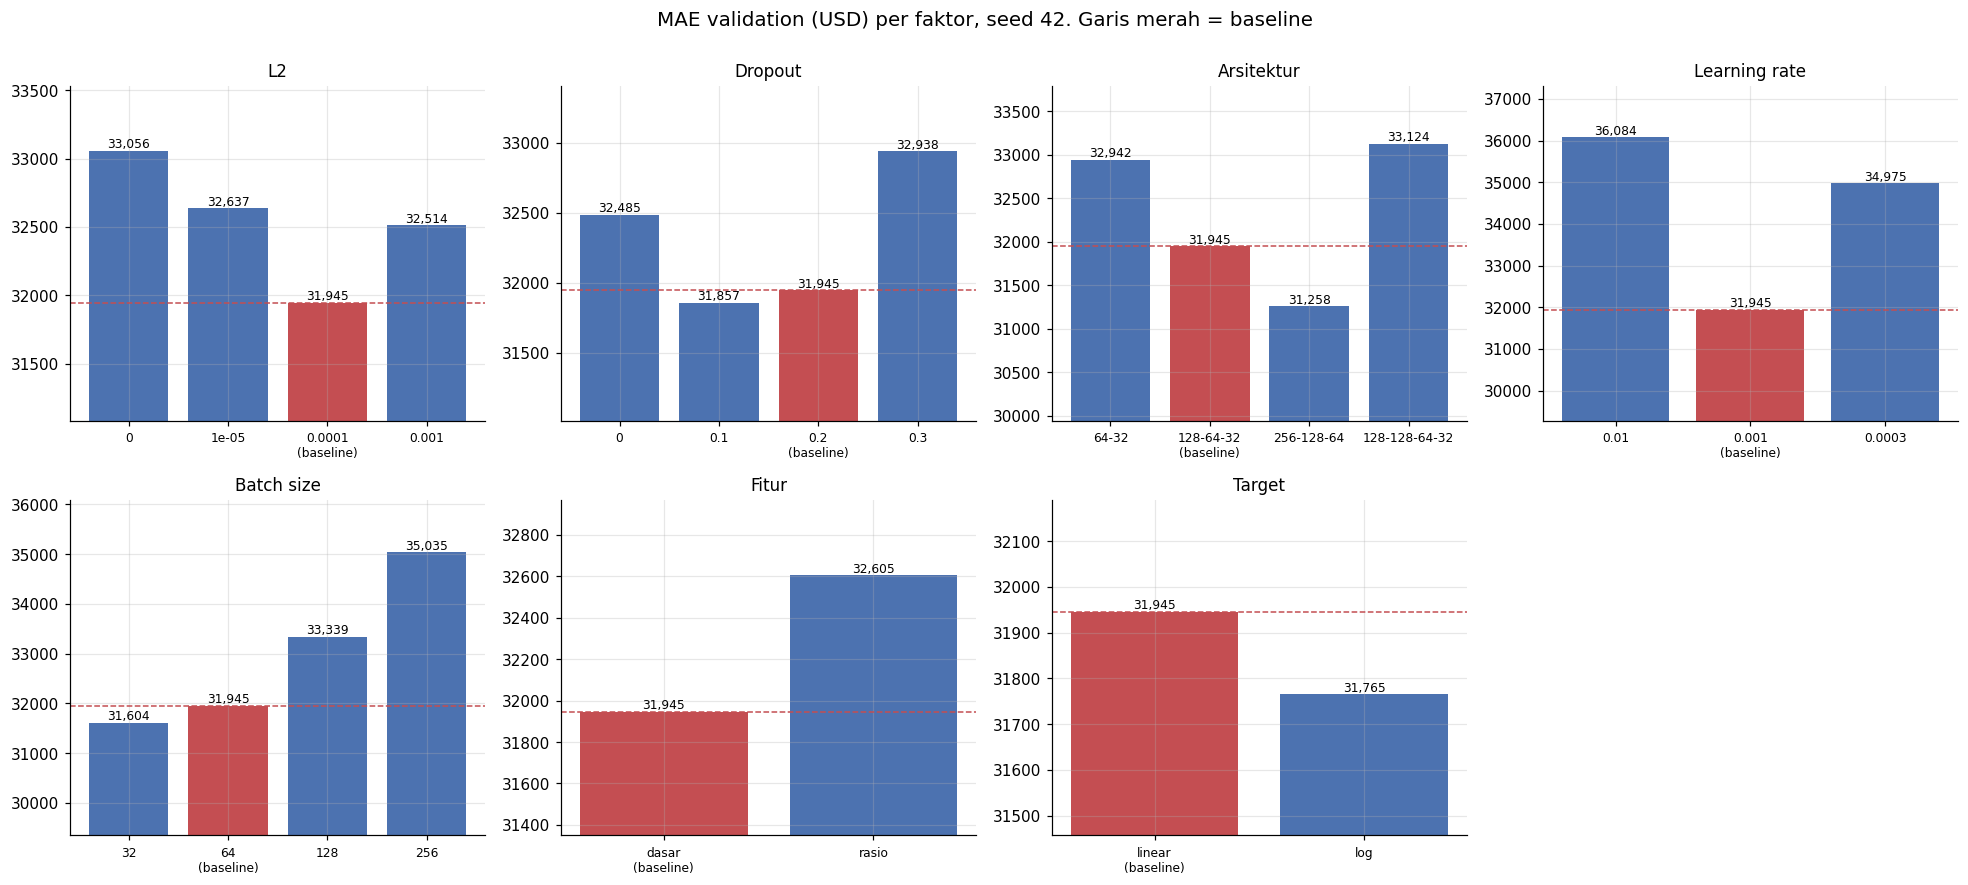

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (factor, (field, values)) in zip(axes.ravel(), LEVELS.items()):
    labels, vals, colors = [], [], []
    for v in values:
        if v == BASE[field]:
            labels.append(lab(v) + "\n(baseline)"); vals.append(base_val); colors.append("#C44E52")
        else:
            labels.append(lab(v))
            vals.append(float(screen[(screen["factor"] == factor) & (screen["setting"] == lab(v))]["val_mae"].iloc[0]))
            colors.append("#4C72B0")
    bars = ax.bar(labels, vals, color=colors)
    ax.bar_label(bars, labels=[f"{x:,.0f}" for x in vals], fontsize=8)
    ax.axhline(base_val, color="#C44E52", ls="--", lw=1)
    lo, hi = min(vals + [base_val]), max(vals + [base_val])
    ax.set_ylim(lo - (hi - lo) * 0.6 - 200, hi + (hi - lo) * 0.25 + 200)
    ax.set_title(factor, fontsize=11)
    ax.tick_params(axis="x", labelsize=8)
axes.ravel()[-1].axis("off")
fig.suptitle(f"MAE validation (USD) per faktor, seed {SEED}. Garis merah = baseline", fontsize=13, y=1.0)
plt.tight_layout()
save_fig("16_eksperimen_per_faktor")
plt.show()

**Cara membaca:** batang yang lebih rendah dari garis merah berarti MAE validation lebih kecil (lebih baik). Sumbu Y **dipotong** supaya
perbedaan kecil terlihat, jadi lihat angkanya, bukan tinggi batangnya. Satu percobaan per nilai belum cukup untuk menyimpulkan: perbedaan
kecil bisa murni karena acak. Itu dinilai di bagian berikutnya.

## 4. Noise Antar-Seed dan Pemilihan per Faktor

Pelatihan yang sama dengan seed berbeda menghasilkan MAE yang sedikit berbeda (inisialisasi bobot, urutan batch, dropout). Besar
variasi ini diukur dari baseline dengan beberapa seed, lalu dipakai sebagai **ambang**: suatu nilai faktor dianggap lebih baik hanya bila
MAE validation-nya lebih rendah dari baseline **melebihi satu simpangan baku noise**. Karena simpangan baku dari sedikit seed bisa kebetulan
sangat kecil, ambang diberi **batas minimal 0,5% dari MAE baseline** agar perbedaan sepele tidak dianggap perbaikan. Bila tidak melebihi
ambang, nilai baseline dipertahankan.

In [9]:
noise_rows = [get_result(BASE, s) for s in SEEDS]
noise_vals = np.array([r["val_mae"] for r in noise_rows])
NOISE = float(noise_vals.std(ddof=1))
print("Baseline per seed :", {s: f"${v:,.0f}" for s, v in zip(SEEDS, noise_vals)})
print(f"Rata-rata         : ${noise_vals.mean():,.0f}")
THRESH = max(NOISE, 0.005 * base_val)        # ambang keputusan: noise antar-seed, minimal 0,5% dari MAE baseline
print(f"Noise (std antar-seed)    : ${NOISE:,.0f}")
print(f"Ambang perbaikan bermakna : ${THRESH:,.0f}  (maks dari noise dan 0,5% x MAE baseline)")

  [ 18] baseline                     seed 7   | val MAE $  31,993 | epoch 125 (terbaik 105) |  105.9 dtk
  [ 19] baseline                     seed 21  | val MAE $  32,537 | epoch 144 (terbaik 124) |  121.9 dtk
Baseline per seed : {42: '$31,945', 7: '$31,993', 21: '$32,537'}
Rata-rata         : $32,158
Noise (std antar-seed)    : $329
Ambang perbaikan bermakna : $329  (maks dari noise dan 0,5% x MAE baseline)


In [10]:
chosen = {}                       # faktor -> baris hasil terbaik, hanya jika perbaikan > noise
decision = []
for factor, (field, values) in LEVELS.items():
    sub = screen[screen["factor"] == factor]
    best = sub.loc[sub["val_mae"].idxmin()]
    gain = base_val - best["val_mae"]
    ok = gain > THRESH
    if ok:
        chosen[factor] = best
    decision.append({"faktor": factor, "nilai_terbaik": best["setting"], "val_mae": best["val_mae"],
                     "perbaikan_USD": gain, "ambang": THRESH,
                     "keputusan": "DIPAKAI" if ok else "tetap baseline"})
display(pd.DataFrame(decision).round(0).set_index("faktor"))

,nilai_terbaik,val_mae,perbaikan_USD,ambang,keputusan
faktor,,,,,
L2,0.001,32514.0,-569.0,329.0,tetap baseline
Dropout,0.1,31857.0,88.0,329.0,tetap baseline
Arsitektur,256-128-64,31258.0,687.0,329.0,DIPAKAI
Learning rate,0.0003,34975.0,-3030.0,329.0,tetap baseline
Batch size,32,31604.0,341.0,329.0,DIPAKAI
Fitur,rasio,32605.0,-659.0,329.0,tetap baseline
Target,log,31765.0,180.0,329.0,tetap baseline


## 5. Kombinasi dan Pemilihan Model Final

Nilai-nilai yang lolos ambang digabung menjadi satu konfigurasi **kombinasi**. Kombinasi, baseline, dan (bila berbeda) satu konfigurasi
**terbaik tunggal** dari screening, masing-masing dilatih dengan semua seed. Model final dipilih dari rata-rata MAE validation, dengan
syarat yang sama: harus lebih baik dari baseline **melebihi ambang**. Bila tidak ada yang lolos, baseline tetap menjadi model final, dan itu
hasil yang sah.

In [11]:
combo = dict(BASE)
labels = []
for factor, row in chosen.items():
    field = LEVELS[factor][0]
    combo[field] = CFG_BY_NAME[row["name"]][field]
    labels.append(f"{factor}={row['setting']}")
combo.update(name="kombinasi", factor="kombinasi", setting=" + ".join(labels) if labels else "baseline")

cands = {"baseline": BASE}
if cfg_key(combo) != cfg_key(BASE):
    cands["kombinasi"] = combo
single = screen.loc[screen["val_mae"].idxmin()]
single_cfg = CFG_BY_NAME[single["name"]]
if base_val - single["val_mae"] > THRESH and cfg_key(single_cfg) not in [cfg_key(c) for c in cands.values()]:
    cands["terbaik_tunggal"] = {**single_cfg, "name": "terbaik_tunggal",
                                "setting": f"{single_cfg['factor']}={single_cfg['setting']}"}

print("Kandidat model final:")
for k, c in cands.items():
    print(f"  {k:<16}: arsitektur {lab(c['units'])} | L2 {c['l2']:g} | dropout {c['dropout']:g} | lr {c['lr']:g} | "
          f"batch {c['batch']} | fitur {c['features']} | target {c['target']}")
print()
for k, c in cands.items():
    for s in SEEDS:
        get_result(c, s)

Kandidat model final:
  baseline        : arsitektur 128-64-32 | L2 0.0001 | dropout 0.2 | lr 0.001 | batch 64 | fitur dasar | target linear
  kombinasi       : arsitektur 256-128-64 | L2 0.0001 | dropout 0.2 | lr 0.001 | batch 32 | fitur dasar | target linear
  terbaik_tunggal : arsitektur 256-128-64 | L2 0.0001 | dropout 0.2 | lr 0.001 | batch 64 | fitur dasar | target linear

  [ 20] kombinasi                    seed 42  | val MAE $  32,112 | epoch 108 (terbaik  88) |  175.2 dtk
  [ 21] kombinasi                    seed 7   | val MAE $  32,196 | epoch 131 (terbaik 111) |  205.8 dtk
  [ 22] kombinasi                    seed 21  | val MAE $  32,452 | epoch 134 (terbaik 114) |  213.1 dtk
  [ 23] terbaik_tunggal              seed 7   | val MAE $  31,072 | epoch 152 (terbaik 132) |  126.9 dtk
  [ 24] terbaik_tunggal              seed 21  | val MAE $  31,891 | epoch 160 (terbaik 140) |  132.8 dtk


,val_mae_mean,val_mae_std,val_rmse_mean,val_r2_mean,gap_mean,epoch_mean,n_seed,perbaikan_vs_baseline,lolos_ambang
kandidat,,,,,,,,,
baseline,32158.0,329.0,48470.0,0.821,2022.0,155.0,3,0.0,False
kombinasi,32253.0,177.0,48281.0,0.822,3130.0,124.0,3,-95.0,False
terbaik_tunggal,31407.0,429.0,48097.0,0.823,3794.0,171.0,3,751.0,True



Model final: 'terbaik_tunggal'  ->  Arsitektur=256-128-64


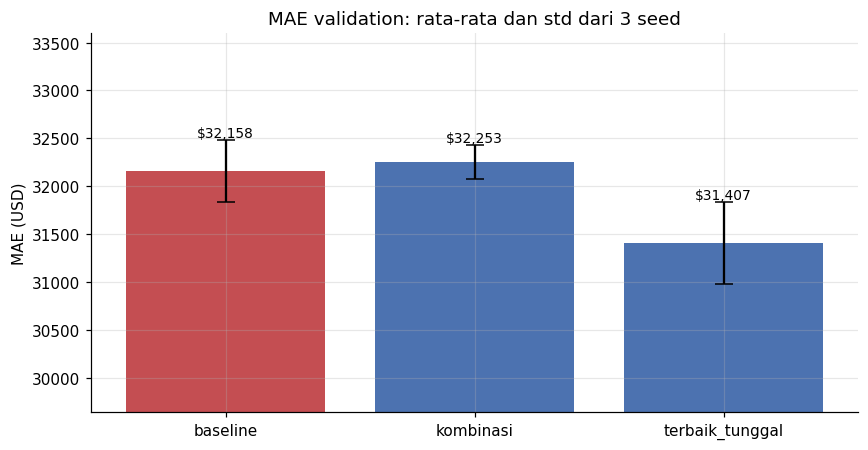

In [12]:
res = pd.DataFrame(ROWS)
summ = []
for k, c in cands.items():
    r = res[(res["key"] == cfg_key(c)) & (res["seed"].isin(SEEDS))]
    summ.append({"kandidat": k, "val_mae_mean": r["val_mae"].mean(), "val_mae_std": r["val_mae"].std(ddof=1),
                 "val_rmse_mean": r["val_rmse"].mean(), "val_r2_mean": r["val_r2"].mean(),
                 "gap_mean": r["gap"].mean(), "epoch_mean": r["epochs"].mean(), "n_seed": len(r)})
summ = pd.DataFrame(summ).set_index("kandidat")
base_mean = float(summ.loc["baseline", "val_mae_mean"])
summ["perbaikan_vs_baseline"] = base_mean - summ["val_mae_mean"]
summ["lolos_ambang"] = summ["perbaikan_vs_baseline"] > THRESH
display(summ.round({"val_mae_mean": 0, "val_mae_std": 0, "val_rmse_mean": 0, "val_r2_mean": 3,
                    "gap_mean": 0, "epoch_mean": 0, "perbaikan_vs_baseline": 0}))

eligible = summ[summ["lolos_ambang"]]
final_name = eligible["val_mae_mean"].idxmin() if len(eligible) else "baseline"
final_cfg = {**cands[final_name]}
print(f"\nModel final: '{final_name}'  ->  {final_cfg['setting']}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(summ.index, summ["val_mae_mean"], yerr=summ["val_mae_std"].fillna(0), capsize=6,
       color=["#C44E52" if k == "baseline" else "#4C72B0" for k in summ.index])
lo, hi = summ["val_mae_mean"].min(), summ["val_mae_mean"].max()
ax.set_ylim(lo - (hi - lo) * 1.5 - 500, hi + (hi - lo) * 1.0 + 500)
ax.set(title=f"MAE validation: rata-rata dan std dari {len(SEEDS)} seed", ylabel="MAE (USD)")
for i, (m, s) in enumerate(zip(summ["val_mae_mean"], summ["val_mae_std"].fillna(0))):
    ax.text(i, m + s, f"${m:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
save_fig("17_kandidat_final")
plt.show()

## 6. Evaluasi Final pada Test

Mulai dari sini **test dipakai**, satu kali, hanya untuk melaporkan. Tidak ada keputusan yang diubah berdasarkan hasil ini.

Model final dan baseline dilatih ulang dengan `seed = 42` agar objek modelnya tersedia untuk prediksi dan penyimpanan. Karena pelatihan
di CPU/GPU tidak sepenuhnya deterministik, angkanya bisa sedikit berbeda dari tabel bagian 5.

Sebagai pembanding, ditambahkan tiga model non-neural pada fitur yang sama dengan model final: regresi linear, Random Forest, dan
Gradient Boosting. Tujuannya memberi konteks, bukan memilih model.

In [13]:
def predict_usd(model, X, cfg):
    return dec_target(model.predict(X, verbose=0).ravel(), cfg["target"])


final_model, final_hist, final_row = run_one(final_cfg, SEED)
base_model, base_hist, base_row2 = run_one(BASE, SEED)

Xtr_f, Xva_f, Xte_f = FEATS[final_cfg["features"]]
Xtr_b, Xva_b, Xte_b = FEATS[BASE["features"]]
pred = {
    "MLP baseline (notebook 03)": (predict_usd(base_model, Xva_b, BASE), predict_usd(base_model, Xte_b, BASE)),
    f"MLP final ({final_name})": (predict_usd(final_model, Xva_f, final_cfg), predict_usd(final_model, Xte_f, final_cfg)),
}

n_trees = 50 if QUICK else 200
others = {
    "Regresi linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=n_trees, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
}
for name, m in others.items():
    m.fit(Xtr_f, Y_TRAIN)
    pred[name] = (m.predict(Xva_f), m.predict(Xte_f))

rows = []
for name, (pv, pt) in pred.items():
    mv, mt = metrics_usd(Y_VAL, pv), metrics_usd(Y_TEST, pt)
    rows.append({"model": name, "val_MAE": mv["MAE"], "test_MAE": mt["MAE"], "test_RMSE": mt["RMSE"], "test_R2": mt["R2"]})
test_tbl = pd.DataFrame(rows).set_index("model")
display(test_tbl.round({"val_MAE": 0, "test_MAE": 0, "test_RMSE": 0, "test_R2": 3}))

bm_path = ROOT / "backend" / "artifacts" / "metrics.json"
if bm_path.exists():
    b = json.loads(bm_path.read_text())
    print(f"Pembanding: model backend/train.py (notebook 03 mencatat) test MAE ${b['test_mae_usd']:,.0f}, R2 {b['test_r2']:.3f}")

,val_MAE,test_MAE,test_RMSE,test_R2
model,,,,
MLP baseline (notebook 03),31945.0,33111.0,49529.0,0.820
MLP final (terbaik_tunggal),31258.0,32427.0,49367.0,0.821
Regresi linear,47257.0,49151.0,68364.0,0.657
Random Forest,31610.0,32640.0,49243.0,0.822
Gradient Boosting,32304.0,33078.0,48677.0,0.826


Pembanding: model backend/train.py (notebook 03 mencatat) test MAE $33,021, R2 0.821


## 7. Analisis Galat dan Kurva Pembelajaran

Notebook 03 menemukan bahwa baseline menaksir **terlalu rendah** harga tinggi dan **terlalu tinggi** harga rendah. Di sini dilihat apakah
model final mengubah pola itu. Blok bernilai tepat \$500.001 (harga terpotong) dilaporkan terpisah karena harga aslinya tidak diketahui.

In [14]:
ev = test_df[["ocean_proximity", TARGET]].reset_index(drop=True).copy()
ev["base"] = pred["MLP baseline (notebook 03)"][1] * TARGET_SCALE
ev["final"] = pred[f"MLP final ({final_name})"][1] * TARGET_SCALE
ev["rentang"] = pd.cut(ev[TARGET], [0, 100_000, 200_000, 300_000, 400_000, 500_000, np.inf],
                       labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k", "500k+"], right=False)
ev["terpotong"] = ev[TARGET] == ev[TARGET].max()

rows = []
for r, g in ev.groupby("rentang", observed=True):
    rows.append({"rentang": r, "jumlah": len(g),
                 "MAE_baseline": (g["base"] - g[TARGET]).abs().mean(), "MAE_final": (g["final"] - g[TARGET]).abs().mean(),
                 "bias_baseline": (g["base"] - g[TARGET]).mean(), "bias_final": (g["final"] - g[TARGET]).mean()})
by_range = pd.DataFrame(rows).set_index("rentang")
display(by_range.round(0).astype({"jumlah": int}))

nc = ~ev["terpotong"]
for name, col in [("baseline", "base"), ("final", "final")]:
    m = metrics_usd(ev.loc[nc, TARGET] / TARGET_SCALE, ev.loc[nc, col] / TARGET_SCALE)
    print(f"Test tanpa blok terpotong ({int(nc.sum()):,} baris), {name:<8}: MAE ${m['MAE']:,.0f} | RMSE ${m['RMSE']:,.0f} | R2 {m['R2']:.3f}")

,jumlah,MAE_baseline,MAE_final,bias_baseline,bias_final
rentang,,,,,
<100k,543,19858.0,18273.0,16927.0,15401.0
100-200k,1242,24415.0,23863.0,10590.0,9518.0
200-300k,727,34674.0,34938.0,-623.0,-863.0
300-400k,306,53306.0,54474.0,-29070.0,-27514.0
400-500k,120,78296.0,75706.0,-69767.0,-66192.0
500k+,159,66184.0,61089.0,-66184.0,-60282.0


Test tanpa blok terpotong (2,944 baris), baseline: MAE $31,594 | RMSE $46,289 | R2 0.779
Test tanpa blok terpotong (2,944 baris), final   : MAE $31,123 | RMSE $46,395 | R2 0.778


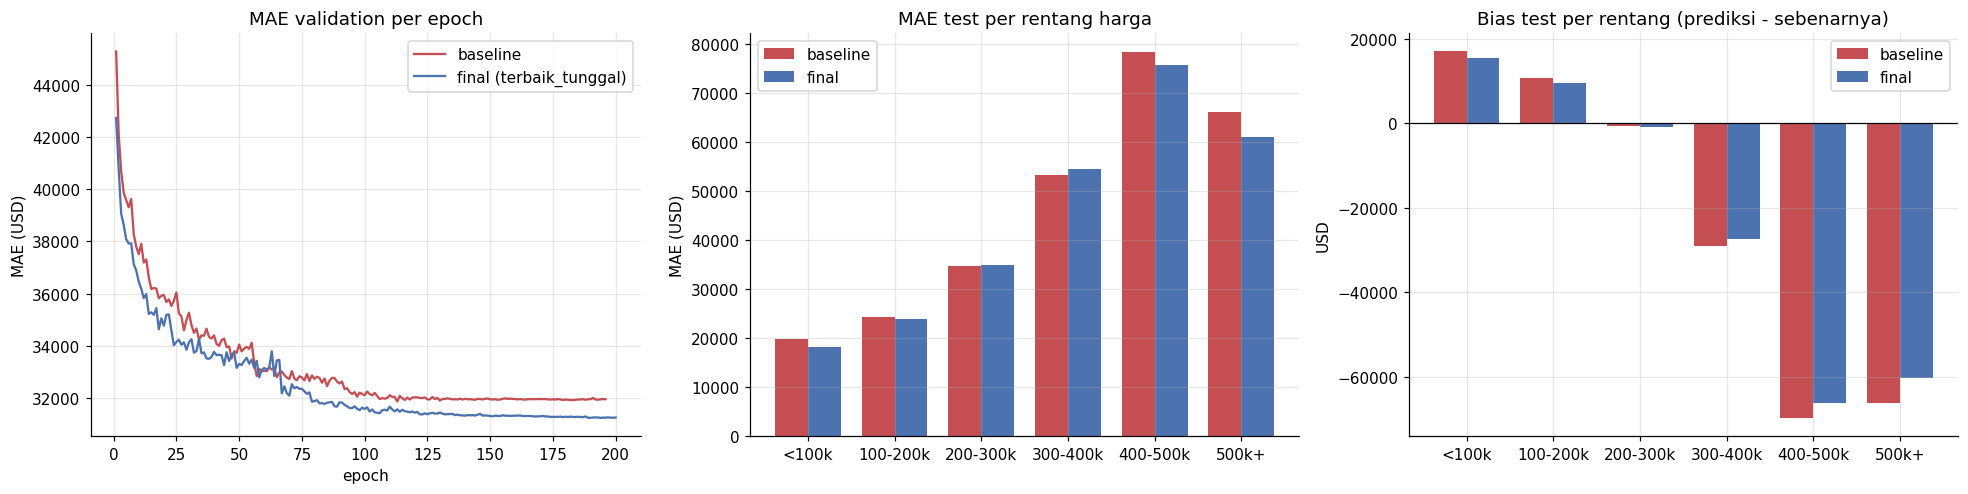

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))

ep_b, ep_f = np.arange(1, len(base_hist["val_mae"]) + 1), np.arange(1, len(final_hist["val_mae"]) + 1)
if final_cfg["target"] == "linear":
    ax[0].plot(ep_b, np.array(base_hist["val_mae"]) * TARGET_SCALE, label="baseline", color="#C44E52")
    ax[0].plot(ep_f, np.array(final_hist["val_mae"]) * TARGET_SCALE, label=f"final ({final_name})", color="#4C72B0")
    ax[0].set(title="MAE validation per epoch", xlabel="epoch", ylabel="MAE (USD)")
else:
    # Skala loss berbeda (target di-log), jadi dibandingkan secara relatif: val_loss / val_loss terbaik tiap model
    ax[0].plot(ep_b, np.array(base_hist["val_loss"]) / np.min(base_hist["val_loss"]), label="baseline", color="#C44E52")
    ax[0].plot(ep_f, np.array(final_hist["val_loss"]) / np.min(final_hist["val_loss"]), label=f"final ({final_name})", color="#4C72B0")
    ax[0].set(title="val_loss relatif terhadap nilai terbaiknya\n(skala asli berbeda karena target di-log)", xlabel="epoch",
              ylabel="val_loss / val_loss terbaik")
ax[0].legend()

x = np.arange(len(by_range)); w = 0.38
ax[1].bar(x - w / 2, by_range["MAE_baseline"], w, label="baseline", color="#C44E52")
ax[1].bar(x + w / 2, by_range["MAE_final"], w, label="final", color="#4C72B0")
ax[1].set_xticks(x, by_range.index); ax[1].set(title="MAE test per rentang harga", ylabel="MAE (USD)"); ax[1].legend()

ax[2].bar(x - w / 2, by_range["bias_baseline"], w, label="baseline", color="#C44E52")
ax[2].bar(x + w / 2, by_range["bias_final"], w, label="final", color="#4C72B0")
ax[2].axhline(0, color="black", lw=0.8)
ax[2].set_xticks(x, by_range.index); ax[2].set(title="Bias test per rentang (prediksi - sebenarnya)", ylabel="USD"); ax[2].legend()

plt.tight_layout()
save_fig("18_baseline_vs_final")
plt.show()

## 8. Menyimpan Model Final

Disimpan di folder `models/`. Folder `backend/artifacts/` **tidak ditimpa**: itu milik model yang sedang dipakai aplikasi.

In [16]:
mv_final = metrics_usd(Y_VAL, pred[f"MLP final ({final_name})"][0])
mt_final = metrics_usd(Y_TEST, pred[f"MLP final ({final_name})"][1])
config = {
    "tanggal": str(date.today()), "keras": keras.__version__, "model_final": final_name,
    "konfigurasi": {**{k: final_cfg[k] for k in HP_KEYS}, "units": list(final_cfg["units"])},
    "target_transform": final_cfg["target"], "fitur": final_cfg["features"],
    "seed_pembagian_data": SEED, "seed_eksperimen": SEEDS, "ambang_noise_usd": NOISE, "ambang_keputusan_usd": THRESH,
    "val_mae_mean_seed": float(summ.loc[final_name, "val_mae_mean"]),
    "val_mae_std_seed": None if pd.isna(summ.loc[final_name, "val_mae_std"]) else float(summ.loc[final_name, "val_mae_std"]),
    "val_seed42": mv_final, "test_seed42": mt_final,
    "n_params": int(final_model.count_params()),
    "catatan": "Jika target_transform = 'log', prediksi harus di-exp lalu dikali 100000. "
               "Jika fitur = 'rasio', preprocessing wajib memakai prep_tuned.json (ada fitur rasio dan clip).",
}

if QUICK:
    print("QUICK = True: model dan konfigurasi TIDAK disimpan ke models/ (hasil uji cepat bukan untuk dipakai).")
else:
    final_model.save(MODEL_DIR / "mlp_tuned.keras")
    (MODEL_DIR / "prep_tuned.json").write_text(json.dumps(PREP[final_cfg["features"]], indent=2))
    (MODEL_DIR / "model_config.json").write_text(json.dumps(config, indent=2, default=float))
    summ.to_csv(RES_DIR / "exp_kandidat_final.csv")
    test_tbl.to_csv(RES_DIR / "exp_test_final.csv")
    for f in sorted(list(MODEL_DIR.glob("*")) + list(RES_DIR.glob("*"))):
        print(f"{f.relative_to(ROOT)}  ({f.stat().st_size / 1024:,.0f} KB)")

models/mlp_tuned.keras  (559 KB)
models/model_config.json  (1 KB)
models/prep_tuned.json  (1 KB)
reports/results/exp_kandidat_final.csv  (1 KB)
reports/results/exp_results.csv  (8 KB)
reports/results/exp_test_final.csv  (0 KB)


### Catatan integrasi ke aplikasi

Aplikasi saat ini (`backend/app.py`) memakai 8 fitur mentah, preprocessing `backend/preprocess.py` (13 kolom), dan prediksi linear. Model
final dari notebook ini hanya bisa menggantikannya jika **kedua sisi disesuaikan**:

- **Bila `fitur = rasio`:** aplikasi harus menghitung tiga rasio dan membatasinya dengan batas di `prep_tuned.json`. `backend/preprocess.py`
  belum mendukung itu. Cara termudah: salin logika `_build`/`fit_prep`/`transform` di bagian 1 ke modul preprocessing aplikasi.
- **Bila `target = log`:** hasil `model.predict` harus dipetakan dengan `exp(...)` lalu dikalikan 100.000.
- **Bila keduanya `dasar` dan `linear`:** model final memakai preprocessing yang sama dengan `prep.json` yang ada, sehingga cukup mengganti
  berkas model dan `prep.json`.

Pastikan versi Keras di server sama dengan versi saat model disimpan (`keras` tercatat di `model_config.json`).

## 9. Kesimpulan Otomatis

Sel di bawah menyusun kesimpulan dari hasil yang benar-benar dihitung di atas, sehingga angkanya selalu cocok dengan tabel.

In [17]:
fn = f"MLP final ({final_name})"
bn = "MLP baseline (notebook 03)"
b_mean, b_std = summ.loc["baseline", "val_mae_mean"], summ.loc["baseline", "val_mae_std"]
f_mean, f_std = summ.loc[final_name, "val_mae_mean"], summ.loc[final_name, "val_mae_std"]
t_b, t_f = test_tbl.loc[bn], test_tbl.loc[fn]
d_test = t_b["test_MAE"] - t_f["test_MAE"]

L = [f"**Ringkasan eksperimen** ({len(SEEDS)} seed: {SEEDS}; noise baseline = ${NOISE:,.0f}; ambang keputusan = ${THRESH:,.0f})", ""]
if final_name == "baseline":
    L += ["- **Tidak ada konfigurasi yang lebih baik dari baseline melebihi ambang**, sehingga baseline tetap menjadi model final.",
          "  Ini hasil yang sah: tidak ada cukup bukti bahwa konfigurasi lain lebih baik, karena perbedaan yang terlihat di screening",
          "  tidak melampaui variasi acak antar-seed."]
else:
    L += [f"- Model final: **{final_cfg['setting']}**.",
          f"- MAE validation (rata-rata {len(SEEDS)} seed): baseline **${b_mean:,.0f}** (std ${0 if pd.isna(b_std) else b_std:,.0f}) "
          f"menjadi **${f_mean:,.0f}** (std ${0 if pd.isna(f_std) else f_std:,.0f}), perbaikan ${b_mean - f_mean:,.0f} "
          f"({(b_mean - f_mean) / b_mean * 100:.1f}%)."]
L += [f"- Pada **test** (seed 42, dipakai sekali): MAE baseline ${t_b['test_MAE']:,.0f} -> final ${t_f['test_MAE']:,.0f} "
      f"(selisih ${d_test:,.0f}); R² {t_b['test_R2']:.3f} -> {t_f['test_R2']:.3f}."]
if final_name != "baseline" and abs(d_test) < THRESH:
    L += [f"- Selisih di test (${abs(d_test):,.0f}) lebih kecil dari ambang keputusan (${THRESH:,.0f}), jadi **jangan dibaca sebagai perbaikan pasti**."]
L += [f"- Perbandingan non-neural pada test: linear ${test_tbl.loc['Regresi linear', 'test_MAE']:,.0f}, "
      f"Random Forest ${test_tbl.loc['Random Forest', 'test_MAE']:,.0f}, "
      f"Gradient Boosting ${test_tbl.loc['Gradient Boosting', 'test_MAE']:,.0f}."]
tiered = pd.DataFrame(decision).set_index("faktor")
used = [f for f in tiered.index if tiered.loc[f, "keputusan"] == "DIPAKAI"]
L += [f"- Faktor yang melampaui ambang: {', '.join(used) if used else 'tidak ada'}."]
L += ["", "**Keterbatasan:** (1) satu kali pembagian data, sehingga hasil bisa berbeda pada pembagian lain; (2) hanya "
      f"{len(SEEDS)} seed untuk mengukur noise, jadi estimasi noise sendiri kasar; (3) pencarian satu-faktor-per-percobaan tidak "
      "menjelajahi seluruh kombinasi; (4) harga terpotong di $500.001 tetap menjadi batas data yang tidak bisa diperbaiki lewat hyperparameter."]
if QUICK:
    L += ["", "> **QUICK = True: angka di atas hanya uji cepat, bukan hasil untuk laporan.**"]
display(Markdown("\n".join(L)))

**Ringkasan eksperimen** (3 seed: [42, 7, 21]; noise baseline = $329; ambang keputusan = $329)

- Model final: **Arsitektur=256-128-64**.
- MAE validation (rata-rata 3 seed): baseline **$32,158** (std $329) menjadi **$31,407** (std $429), perbaikan $751 (2.3%).
- Pada **test** (seed 42, dipakai sekali): MAE baseline $33,111 -> final $32,427 (selisih $684); R² 0.820 -> 0.821.
- Perbandingan non-neural pada test: linear $49,151, Random Forest $32,640, Gradient Boosting $33,078.
- Faktor yang melampaui ambang: Arsitektur, Batch size.

**Keterbatasan:** (1) satu kali pembagian data, sehingga hasil bisa berbeda pada pembagian lain; (2) hanya 3 seed untuk mengukur noise, jadi estimasi noise sendiri kasar; (3) pencarian satu-faktor-per-percobaan tidak menjelajahi seluruh kombinasi; (4) harga terpotong di $500.001 tetap menjadi batas data yang tidak bisa diperbaiki lewat hyperparameter.